In [1]:
import joblib
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
df = pd.read_parquet(r"data\model_dfs\basin_daily_model.parquet")

In [3]:
gwl_df = pd.read_parquet(r"data\model_dfs\basin_gwl_daily.parquet")

In [4]:
# date is datetime
df['date'] = pd.to_datetime(df['date'])

# day of year
df['doy'] = df['date'].dt.dayofyear

# 20th-percentile SWE for each day of year
df['swe_low_threshold'] = (
    df
    .groupby('doy')['basin_swe']
    .transform(lambda x: x.quantile(0.20))
)

# binary low-snow target
df['target'] = (
    df['basin_swe']
    <= df['swe_low_threshold']
).astype(int)

## Load the K-Means clustering model

In [5]:
kmeans_bundle = joblib.load(
    "data/models/kmeans_climate_regimes.joblib"
)

kmeans_model = kmeans_bundle["model"]
kmeans_scaler = kmeans_bundle["scaler"]
kmeans_features = kmeans_bundle["features"]
cluster_names = kmeans_bundle["cluster_names"]

print("K-means features:")
print(kmeans_features)

print("\nCluster names:")
print(cluster_names)

K-means features:
['temp_mean', 'temp_14d_mean', 'precip_7d', 'precip_14d', 'precip_30d', 'doy_sin', 'doy_cos']

Cluster names:
{0: 'Cold / Dry', 1: 'Warm / Dry', 2: 'Warm / Wet', 3: 'Cool / Transitional'}


## Load the tuned SVR:

In [6]:
svr_bundle = joblib.load(
    "data/models/svr_swe_bundle.joblib"
)

svr_model = svr_bundle["model"]
svr_x_scaler = svr_bundle["x_scaler"]
svr_y_scaler = svr_bundle["y_scaler"]
svr_features = svr_bundle["features"]
svr_features

['temp_mean',
 'temp_14d_mean',
 'precip_7d',
 'precip_14d',
 'precip_30d',
 'doy_sin',
 'doy_cos']

## Load the tuned SVM:

In [7]:
bundle = joblib.load(
    "data/models/svm_gwl_bundle.joblib"
)

svm_gwl_model = bundle["model"]
svm_gwl_scaler = bundle["scaler"]
features_svm = bundle["features"]

In [8]:
features_svm

['basin_swe',
 'swe_30d_lag',
 'swe_60d_lag',
 'swe_90d_lag',
 'temp_14d_mean',
 'precip_30d',
 'precip_90d',
 'precip_180d',
 'doy_sin',
 'doy_cos']

## Load the RCP data:

In [9]:
scenario_dir = Path(
    "data/scenario/NA_CORDEX"
)

rcp45_temp = pd.read_parquet(
    scenario_dir / "rcp45_temp_daily.parquet"
)

rcp45_prec = pd.read_parquet(
    scenario_dir / "rcp45_prec_daily.parquet"
)

rcp85_temp = pd.read_parquet(
    scenario_dir / "rcp85_temp_daily.parquet"
)

rcp85_prec = pd.read_parquet(
    scenario_dir / "rcp85_prec_daily.parquet"
)

In [10]:
# check items
for name, df_ in {
    "rcp45_temp": rcp45_temp,
    "rcp45_prec": rcp45_prec,
    "rcp85_temp": rcp85_temp,
    "rcp85_prec": rcp85_prec
}.items():

    print("\n", "=" * 50)
    print(name)
    print("Shape:", df_.shape)
    print("Columns:")
    print(df_.columns.tolist())
    print("\nFirst rows:")
    print(df_.head())


rcp45_temp
Shape: (69396, 3)
Columns:
['member_id', 'time', 'temp']

First rows:
         member_id                time       temp
0  CanESM2.CanRCM4 2006-01-01 12:00:00  -4.808696
1  CanESM2.CanRCM4 2006-01-02 12:00:00  -9.985472
2  CanESM2.CanRCM4 2006-01-03 12:00:00 -13.118541
3  CanESM2.CanRCM4 2006-01-04 12:00:00 -16.281033
4  CanESM2.CanRCM4 2006-01-05 12:00:00 -10.506702

rcp45_prec
Shape: (69396, 3)
Columns:
['member_id', 'time', 'prec']

First rows:
         member_id                time      prec
0  CanESM2.CanRCM4 2006-01-01 12:00:00  3.950962
1  CanESM2.CanRCM4 2006-01-02 12:00:00  5.279758
2  CanESM2.CanRCM4 2006-01-03 12:00:00  0.422885
3  CanESM2.CanRCM4 2006-01-04 12:00:00  0.169001
4  CanESM2.CanRCM4 2006-01-05 12:00:00  1.009674

rcp85_temp
Shape: (69396, 3)
Columns:
['member_id', 'time', 'temp']

First rows:
         member_id                time       temp
0  CanESM2.CanRCM4 2006-01-01 12:00:00  -4.818466
1  CanESM2.CanRCM4 2006-01-02 12:00:00  -9.942457
2  CanESM2

# Merge RCP temp and precipiation, engineer featurs

In [11]:
rcp45 = rcp45_temp.merge(
    rcp45_prec,
    on=['member_id', 'time'],
    how='inner'
)

rcp85 = rcp85_temp.merge(
    rcp85_prec,
    on=['member_id', 'time'],
    how='inner'
)

print(rcp45.shape)
print(rcp85.shape)

rcp45.head()

(69396, 4)
(69396, 4)


,member_id,time,temp,prec
0,CanESM2.CanRCM4,2006-01-01 12:00:00,-4.808696,3.950962
1,CanESM2.CanRCM4,2006-01-02 12:00:00,-9.985472,5.279758
2,CanESM2.CanRCM4,2006-01-03 12:00:00,-13.118541,0.422885
3,CanESM2.CanRCM4,2006-01-04 12:00:00,-16.281033,0.169001
4,CanESM2.CanRCM4,2006-01-05 12:00:00,-10.506702,1.009674


In [12]:
# convert units

for df_ in [rcp45, rcp85]:

    # Celsius -> Fahrenheit
    df_['temp_mean'] = (
        df_['temp'] * 9/5 + 32
    )

    # mm/day -> inches/day
    df_['precipitation'] = (
        df_['prec'] / 25.4
    )

In [13]:
# convert time and sort by simulation and date
for df_ in [rcp45, rcp85]:

    df_['time'] = pd.to_datetime(
        df_['time']
    )

    df_.sort_values(
        ['member_id', 'time'],
        inplace=True
    )

    df_.reset_index(
        drop=True,
        inplace=True
    )

In [14]:
# feature engineering function
def create_rcp_features(df):

    df = df.copy()

    # 14 day mean temp
    df['temp_14d_mean'] = (
        df.groupby('member_id')['temp_mean']
        .transform(
            lambda x:
            x.rolling(
                14,
                min_periods=10
            ).mean()
        )
    )

    # rolling precip
    df['precip_7d'] = (
        df.groupby('member_id')['precipitation']
        .transform(
            lambda x:
            x.rolling(
                7,
                min_periods=5
            ).sum()
        )
    )

    df['precip_14d'] = (
        df.groupby('member_id')['precipitation']
        .transform(
            lambda x:
            x.rolling(
                14,
                min_periods=10
            ).sum()
        )
    )

    df['precip_30d'] = (
        df.groupby('member_id')['precipitation']
        .transform(
            lambda x:
            x.rolling(
                30,
                min_periods=20
            ).sum()
        )
    )

    df['precip_90d'] = (
        df.groupby('member_id')['precipitation']
        .transform(
            lambda x:
            x.rolling(
                90,
                min_periods=60
            ).sum()
        )
    )

    
    df['precip_180d'] = (
        df.groupby('member_id')['precipitation']
        .transform(
            lambda x:
            x.rolling(
                180,
                min_periods=120
            ).sum()
        )
    )

    # seasonal variables
    df['day_of_year'] = (
        df['time'].dt.dayofyear
    )

    df['doy_sin'] = np.sin(
        2 * np.pi *
        df['day_of_year'] /
        365.25
    )

    df['doy_cos'] = np.cos(
        2 * np.pi *
        df['day_of_year'] /
        365.25
    )



    return df

In [15]:
rcp45 = create_rcp_features(
    rcp45
)

rcp85 = create_rcp_features(
    rcp85
)

In [16]:
print(rcp45[svr_features].head(20))

print(
    rcp45[svr_features]
    .isna()
    .sum()
)

    temp_mean  temp_14d_mean  precip_7d  precip_14d  precip_30d   doy_sin  \
0   23.344347            NaN        NaN         NaN         NaN  0.017202   
1   14.026150            NaN        NaN         NaN         NaN  0.034398   
2    8.386627            NaN        NaN         NaN         NaN  0.051584   
3    2.694141            NaN        NaN         NaN         NaN  0.068755   
4   13.087936            NaN   0.426468         NaN         NaN  0.085906   
5   12.131935            NaN   0.472104         NaN         NaN  0.103031   
6    7.607357            NaN   0.513800         NaN         NaN  0.120126   
7   10.720894            NaN   0.398604         NaN         NaN  0.137185   
8    5.004745            NaN   0.194745         NaN         NaN  0.154204   
9   12.688251      10.969238   0.179553    0.559616         NaN  0.171177   
10  16.727680      11.492733   0.202696    0.589412         NaN  0.188099   
11  17.436810      11.988073   0.297880    0.724348         NaN  0.204966   

In [17]:
# make model ready copies
rcp45_model = (
    rcp45
    .dropna(
        subset=svr_features
    )
    .copy()
)

rcp85_model = (
    rcp85
    .dropna(
        subset=svr_features
    )
    .copy()
)

print(rcp45_model.shape)
print(rcp85_model.shape)

(69312, 15)
(69312, 15)


# SVR

In [18]:
# scale future predictors with historical SVR scaler
X45 = svr_x_scaler.transform(
    rcp45_model[svr_features]
)

X85 = svr_x_scaler.transform(
    rcp85_model[svr_features]
)

# predict scaled swe
y45_scaled = svr_model.predict(X45)
y85_scaled = svr_model.predict(X85)

# convert back to original swe units
rcp45_model['predicted_swe'] = (
    svr_y_scaler
    .inverse_transform(
        y45_scaled.reshape(-1, 1)
    )
    .ravel()
)

rcp85_model['predicted_swe'] = (
    svr_y_scaler
    .inverse_transform(
        y85_scaled.reshape(-1, 1)
    )
    .ravel()
)

In [19]:
# year
rcp45_model['year'] = rcp45_model['time'].dt.year
rcp85_model['year'] = rcp85_model['time'].dt.year

# annual mean swe for each climate model
rcp45_annual = (
    rcp45_model
    .groupby(['member_id', 'year'])['predicted_swe']
    .mean()
    .reset_index()
)

rcp85_annual = (
    rcp85_model
    .groupby(['member_id', 'year'])['predicted_swe']
    .mean()
    .reset_index()
)

# mean across the two models
rcp45_mean = (
    rcp45_annual
    .groupby('year')['predicted_swe']
    .mean()
)

rcp85_mean = (
    rcp85_annual
    .groupby('year')['predicted_swe']
    .mean()
)

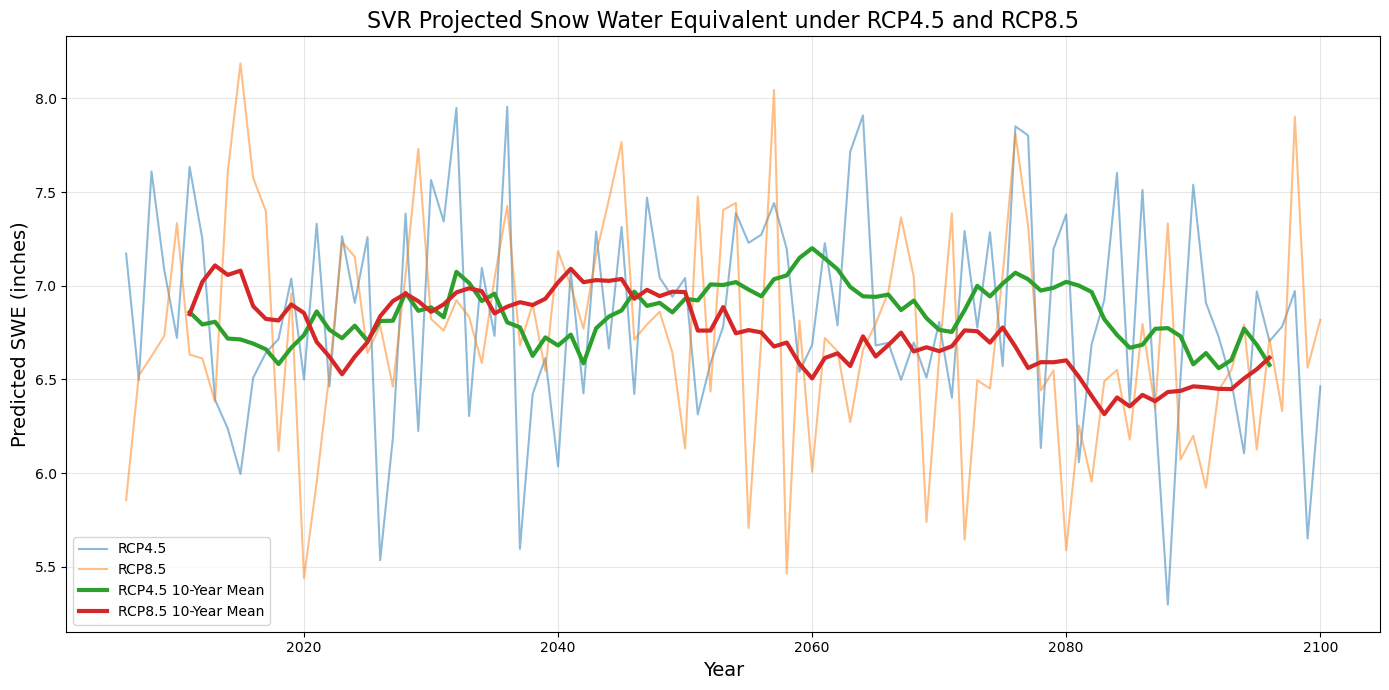

<Figure size 640x480 with 0 Axes>

In [20]:
plt.figure(figsize=(14, 7))

plt.plot(
    rcp45_mean.index,
    rcp45_mean,
    label='RCP4.5',
    alpha=0.5
)

plt.plot(
    rcp85_mean.index,
    rcp85_mean,
    label='RCP8.5',
    alpha=0.5
)

# 10-year rolling trends
plt.plot(
    rcp45_mean.index,
    rcp45_mean.rolling(10, center=True).mean(),
    linewidth=3,
    label='RCP4.5 10-Year Mean'
)

plt.plot(
    rcp85_mean.index,
    rcp85_mean.rolling(10, center=True).mean(),
    linewidth=3,
    label='RCP8.5 10-Year Mean'
)

plt.xlabel('Year', fontsize=14)
plt.ylabel('Predicted SWE (inches)', fontsize=14)
plt.title(
    'SVR Projected Snow Water Equivalent under RCP4.5 and RCP8.5',
    fontsize=16
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

plt.savefig(
    "figures/svr_rcp45_rcp85_swe_projection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
# add month and year
for d in [rcp45_model, rcp85_model]:
    d['year'] = d['time'].dt.year
    d['month'] = d['time'].dt.month

In [22]:
# april swe only
rcp45_april = (
    rcp45_model[rcp45_model['month'] == 4]
    .groupby(['member_id', 'year'])['predicted_swe']
    .mean()
    .reset_index()
)

rcp85_april = (
    rcp85_model[rcp85_model['month'] == 4]
    .groupby(['member_id', 'year'])['predicted_swe']
    .mean()
    .reset_index()
)

In [23]:
rcp45_april_mean = (
    rcp45_april
    .groupby('year')['predicted_swe']
    .mean()
)

rcp85_april_mean = (
    rcp85_april
    .groupby('year')['predicted_swe']
    .mean()
)

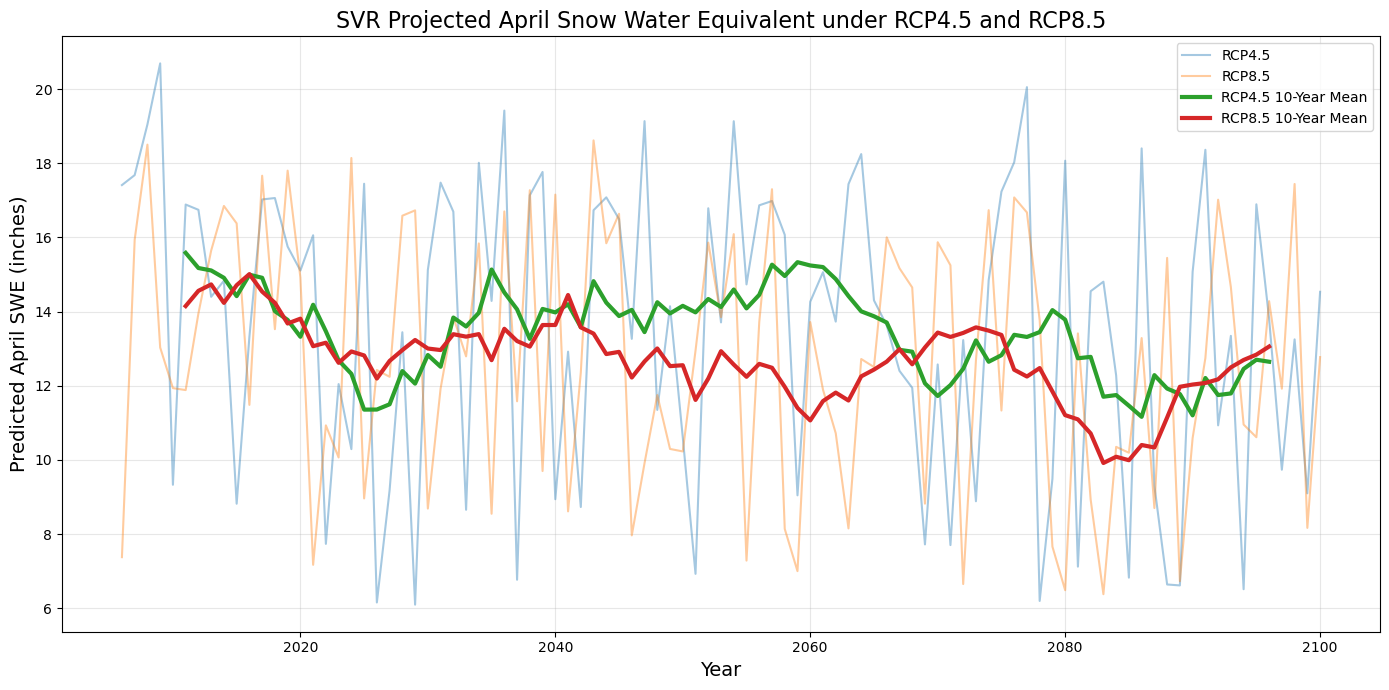

<Figure size 640x480 with 0 Axes>

In [24]:
plt.figure(figsize=(14, 7))

# april values
plt.plot(
    rcp45_april_mean.index,
    rcp45_april_mean,
    alpha=0.4,
    label='RCP4.5'
)

plt.plot(
    rcp85_april_mean.index,
    rcp85_april_mean,
    alpha=0.4,
    label='RCP8.5'
)

# 10 year rolling means
plt.plot(
    rcp45_april_mean.index,
    rcp45_april_mean.rolling(10, center=True).mean(),
    linewidth=3,
    label='RCP4.5 10-Year Mean'
)

plt.plot(
    rcp85_april_mean.index,
    rcp85_april_mean.rolling(10, center=True).mean(),
    linewidth=3,
    label='RCP8.5 10-Year Mean'
)

plt.xlabel('Year', fontsize=14)
plt.ylabel('Predicted April SWE (inches)', fontsize=14)

plt.title(
    'SVR Projected April Snow Water Equivalent under RCP4.5 and RCP8.5',
    fontsize=16
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/svr_april_swe_projection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.savefig(
    "figures/april_svr_rcp45_rcp85_swe_projection.png",
    dpi=300,
    bbox_inches="tight"
)

### Use projections to add in groundwater

In [25]:
rcp45_model[:2]

,member_id,time,temp,prec,temp_mean,precipitation,temp_14d_mean,precip_7d,precip_14d,precip_30d,precip_90d,precip_180d,day_of_year,doy_sin,doy_cos,predicted_swe,year,month
19,CanESM2.CanRCM4,2006-01-20 12:00:00,-5.146003,0.0000,22.737194,0.00000,15.073766,0.181261,0.548472,1.020576,NaN,NaN,20,0.337301,0.941397,10.560040,2006,1
20,CanESM2.CanRCM4,2006-01-21 12:00:00,-0.894403,0.4798,30.390076,0.01889,16.701103,0.103656,0.525666,1.039466,NaN,NaN,21,0.353445,0.935455,11.398262,2006,1


In [38]:
rcp45_model = rcp45_model.sort_values(
    ['member_id', 'time']
).copy()

rcp85_model = rcp85_model.sort_values(
    ['member_id', 'time']
).copy()

In [39]:
rcp85_model.columns

Index(['member_id', 'time', 'temp', 'prec', 'temp_mean', 'precipitation',
       'temp_14d_mean', 'precip_7d', 'precip_14d', 'precip_30d', 'precip_90d',
       'precip_180d', 'day_of_year', 'doy_sin', 'doy_cos', 'predicted_swe',
       'year', 'month', 'basin_swe', 'swe_30d_lag', 'swe_60d_lag',
       'swe_90d_lag'],
      dtype='object')

In [40]:
rcp45_model['basin_swe'] = rcp45_model['predicted_swe']

In [41]:
rcp85_model['basin_swe'] = rcp85_model['predicted_swe']

In [42]:
rcp45_model['precipitation'] = (
    rcp45_model['precipitation'].fillna(0)
)

rcp85_model['precipitation'] = (
    rcp85_model['precipitation'].fillna(0)
)

In [46]:
features_gwl = [
    'basin_swe',
    'swe_30d_lag',
    'swe_60d_lag',
    'swe_90d_lag',
    'temp_14d_mean',
    'precip_30d',
    'precip_90d',
    'precip_180d',
    'doy_sin',
    'doy_cos'
]

In [43]:
for df_rcp in [rcp45_model, rcp85_model]:

    df_rcp['swe_30d_lag'] = (
        df_rcp.groupby('member_id')['basin_swe']
        .shift(30)
    )

    df_rcp['swe_60d_lag'] = (
        df_rcp.groupby('member_id')['basin_swe']
        .shift(60)
    )

    df_rcp['swe_90d_lag'] = (
        df_rcp.groupby('member_id')['basin_swe']
        .shift(90)
    )

In [52]:
rcp45_gwl = (
    rcp45_model
    .dropna(subset=features_gwl)
    .copy()
)

rcp85_gwl = (
    rcp85_model
    .dropna(subset=features_gwl)
    .copy()
)

In [55]:
X45_gwl = rcp45_gwl[features_gwl]
X85_gwl = rcp85_gwl[features_gwl]

X45_gwl_scaled = svm_gwl_scaler.transform(X45_gwl)
X85_gwl_scaled = svm_gwl_scaler.transform(X85_gwl)

rcp45_gwl['predicted_gwl_drought'] = (
    svm_gwl_model.predict(X45_gwl_scaled)
)

rcp85_gwl['predicted_gwl_drought'] = (
    svm_gwl_model.predict(X85_gwl_scaled)
)

rcp45_gwl['gwl_drought_probability'] = (
    svm_gwl_model.predict_proba(X45_gwl_scaled)[:, 1]
)

rcp85_gwl['gwl_drought_probability'] = (
    svm_gwl_model.predict_proba(X85_gwl_scaled)[:, 1]
)

In [56]:
gwl_df.columns

Index(['date', 'basin_swe', 'basin_precip_increment', 'n_snow_stations',
       'swe_30d_lag', 'swe_60d_lag', 'swe_90d_lag', 'temp_mean',
       'temp_mean_lag1', 'temp_7d_mean', 'temp_14d_mean', 'precipitation',
       'precip_lag1', 'precip_7d', 'precip_14d', 'precip_30d', 'precip_90d',
       'precip_180d', 'temp_precip_interaction', 'doy_sin', 'doy_cos',
       'n_climate_stations', 'gwl'],
      dtype='object')

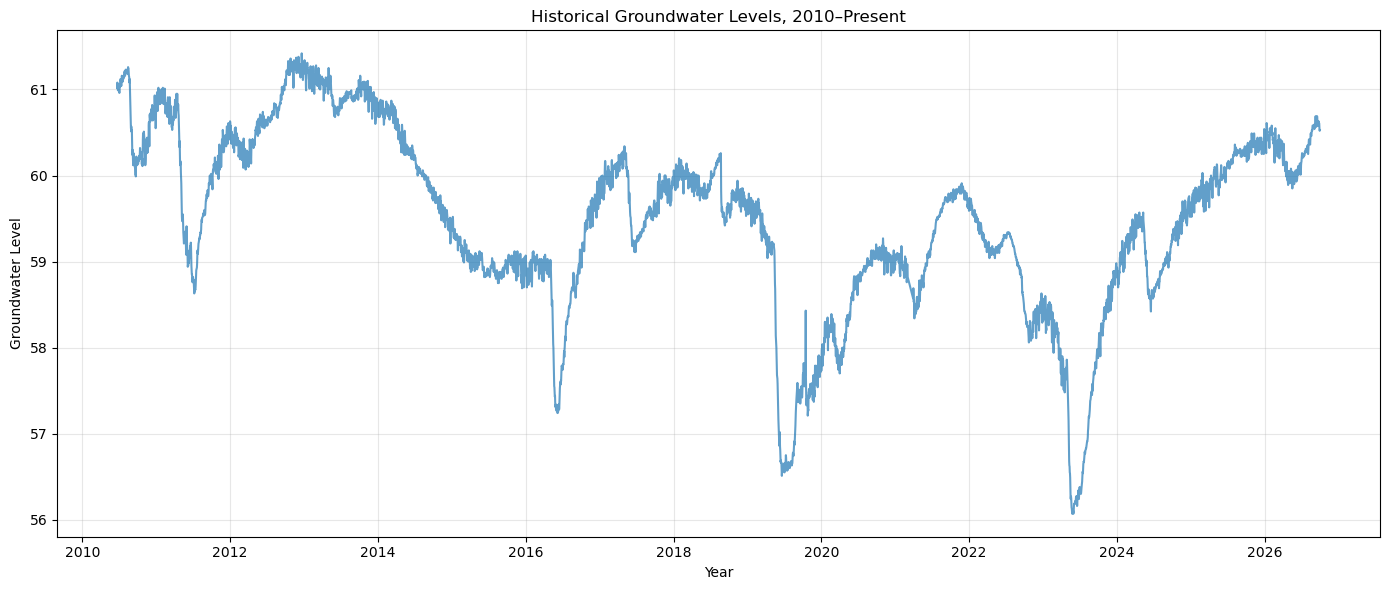

In [57]:
gwl_df['date'] = pd.to_datetime(gwl_df['date'])

gwl_plot = gwl_df[
    gwl_df['date'] >= '2010-01-01'
].dropna(subset=['gwl']).copy()

plt.figure(figsize=(14, 6))

plt.plot(
    gwl_plot['date'],
    gwl_plot['gwl'],
    alpha=0.7
)

plt.xlabel('Year')
plt.ylabel('Groundwater Level')
plt.title('Historical Groundwater Levels, 2010–Present')

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'figures/historical_groundwater_levels.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [60]:
rcp45_gwl_annual = (
    rcp45_gwl
    .groupby(['member_id', 'year'])['gwl_drought_probability']
    .mean()
    .reset_index()
)

rcp85_gwl_annual = (
    rcp85_gwl
    .groupby(['member_id', 'year'])['gwl_drought_probability']
    .mean()
    .reset_index()
)

In [61]:
rcp45_gwl_mean = (
    rcp45_gwl_annual
    .groupby('year')['gwl_drought_probability']
    .mean()
)

rcp85_gwl_mean = (
    rcp85_gwl_annual
    .groupby('year')['gwl_drought_probability']
    .mean()
)

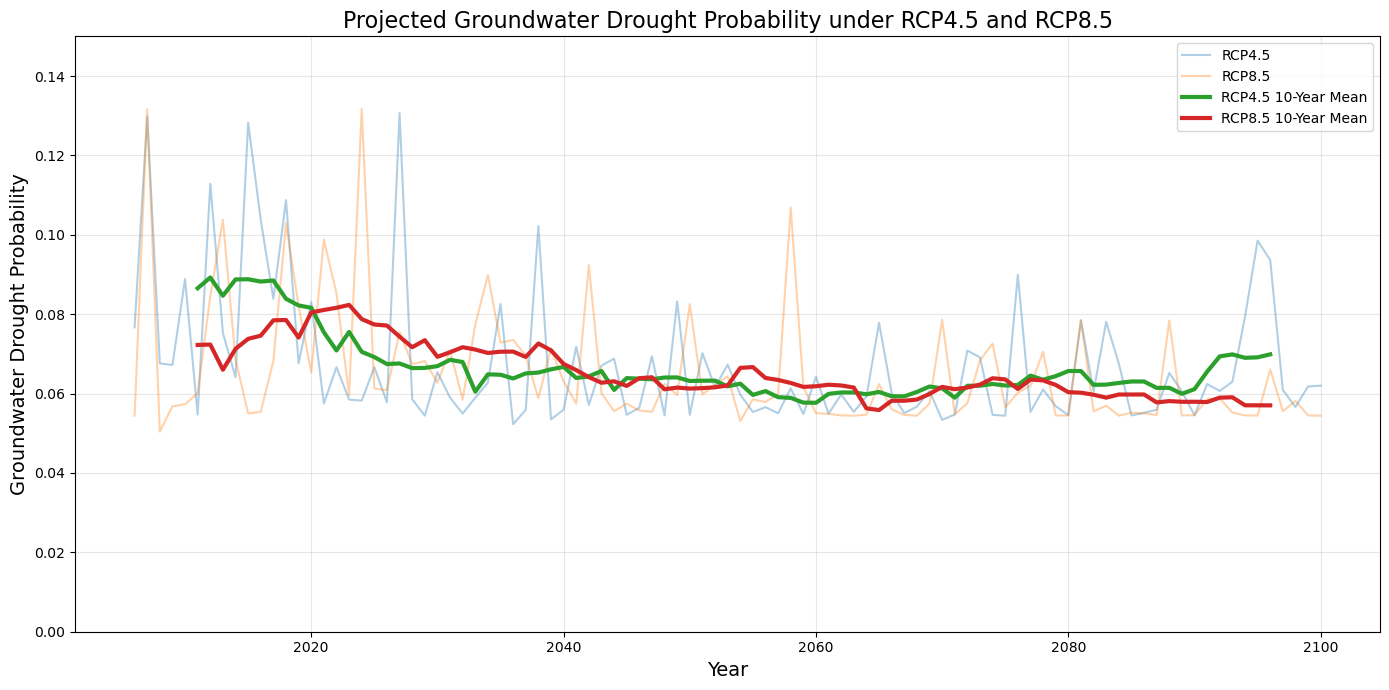

In [66]:
plt.figure(figsize=(14, 7))

# Annual probabilities
plt.plot(
    rcp45_gwl_mean.index,
    rcp45_gwl_mean,
    alpha=0.35,
    label='RCP4.5'
)

plt.plot(
    rcp85_gwl_mean.index,
    rcp85_gwl_mean,
    alpha=0.35,
    label='RCP8.5'
)

# 10-year trends
plt.plot(
    rcp45_gwl_mean.index,
    rcp45_gwl_mean.rolling(10, center=True).mean(),
    linewidth=3,
    label='RCP4.5 10-Year Mean'
)

plt.plot(
    rcp85_gwl_mean.index,
    rcp85_gwl_mean.rolling(10, center=True).mean(),
    linewidth=3,
    label='RCP8.5 10-Year Mean'
)

plt.xlabel('Year', fontsize=14)
plt.ylabel('Groundwater Drought Probability', fontsize=14)

plt.title(
    'Projected Groundwater Drought Probability under RCP4.5 and RCP8.5',
    fontsize=16
)

plt.ylim(0, .15)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'figures/gwl_drought_projection.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# K-means

In [71]:
# scale future features with hist kmeans scaler
X45_kmeans = kmeans_scaler.transform(
    rcp45_model[kmeans_features]
)

X85_kmeans = kmeans_scaler.transform(
    rcp85_model[kmeans_features]
)

# assign historical climate 
rcp45_model['cluster'] = (
    kmeans_model.predict(X45_kmeans)
)

rcp85_model['cluster'] = (
    kmeans_model.predict(X85_kmeans)
)

# names
rcp45_model['cluster_name'] = (
    rcp45_model['cluster']
    .map(cluster_names)
)

rcp85_model['cluster_name'] = (
    rcp85_model['cluster']
    .map(cluster_names)
)

In [72]:
print("RCP4.5 low-snow predictions:")
print(
    rcp45_model['low_snow_pred']
    .value_counts(normalize=True)
)

print("\nRCP8.5 low-snow predictions:")
print(
    rcp85_model['low_snow_pred']
    .value_counts(normalize=True)
)

RCP4.5 low-snow predictions:
low_snow_pred
0    0.765625
1    0.234375
Name: proportion, dtype: float64

RCP8.5 low-snow predictions:
low_snow_pred
0    0.772262
1    0.227738
Name: proportion, dtype: float64


In [73]:
print("\nRCP4.5 climate regimes:")
print(
    rcp45_model['cluster_name']
    .value_counts(normalize=True)
)

print("\nRCP8.5 climate regimes:")
print(
    rcp85_model['cluster_name']
    .value_counts(normalize=True)
)


RCP4.5 climate regimes:
cluster_name
Warm / Wet             0.535203
Cold / Dry             0.238718
Warm / Dry             0.118753
Cool / Transitional    0.107326
Name: proportion, dtype: float64

RCP8.5 climate regimes:
cluster_name
Warm / Wet             0.555733
Cold / Dry             0.218591
Warm / Dry             0.119157
Cool / Transitional    0.106518
Name: proportion, dtype: float64


In [74]:
for df_ in [rcp45_model, rcp85_model]:
    df_['year'] = df_['time'].dt.year

In [75]:
# annual climate cluster frequency RCP4.5
rcp45_cluster_annual = (
    rcp45_model
    .groupby(['year', 'cluster_name'])
    .size()
    .reset_index(name='count')
)

rcp45_cluster_annual['fraction'] = (
    rcp45_cluster_annual['count'] /
    rcp45_cluster_annual.groupby('year')['count'].transform('sum')
)


# annual climate cluster frequency for RCP8.5
rcp85_cluster_annual = (
    rcp85_model
    .groupby(['year', 'cluster_name'])
    .size()
    .reset_index(name='count')
)

rcp85_cluster_annual['fraction'] = (
    rcp85_cluster_annual['count'] /
    rcp85_cluster_annual.groupby('year')['count'].transform('sum')
)

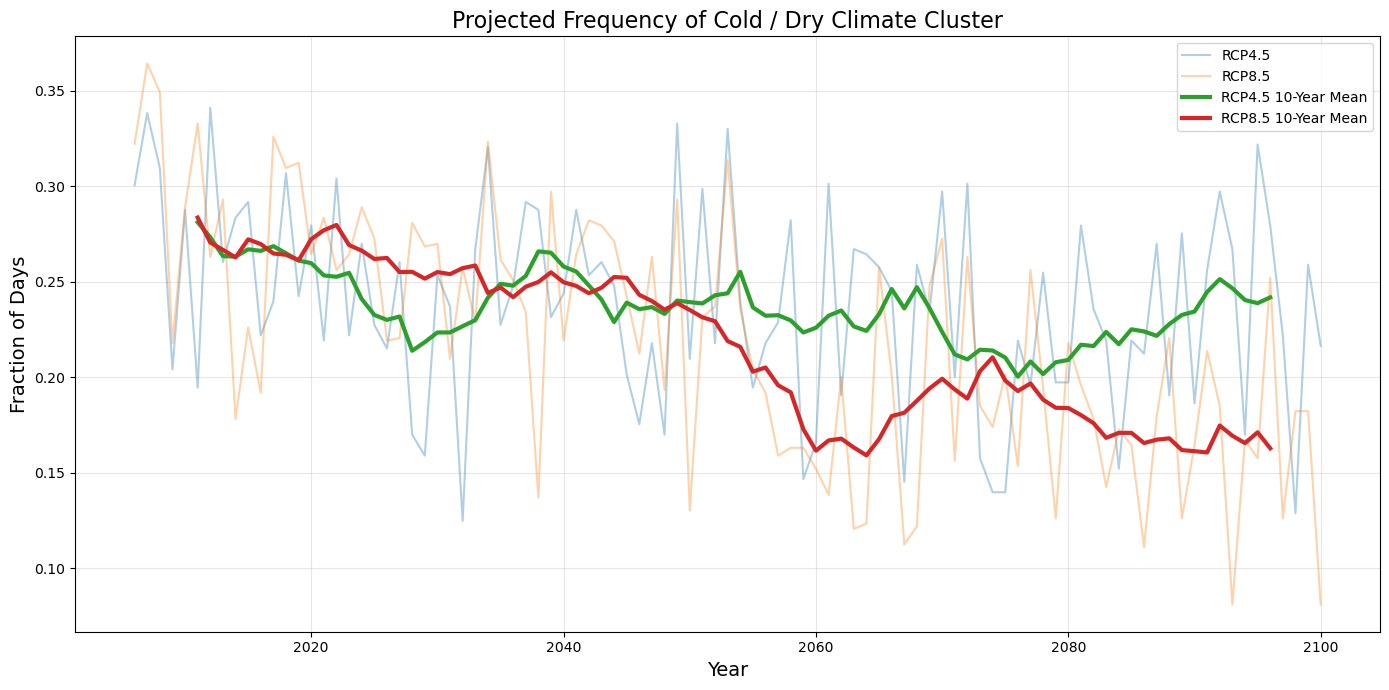

In [79]:
# name and plot

cold45 = (
    rcp45_cluster_annual[
        rcp45_cluster_annual['cluster_name'] == 'Cold / Dry'
    ]
    .set_index('year')['fraction']
)

cold85 = (
    rcp85_cluster_annual[
        rcp85_cluster_annual['cluster_name'] == 'Cold / Dry'
    ]
    .set_index('year')['fraction']
)

plt.figure(figsize=(14, 7))

plt.plot(
    cold45.index,
    cold45,
    alpha=0.35,
    label='RCP4.5'
)

plt.plot(
    cold85.index,
    cold85,
    alpha=0.35,
    label='RCP8.5'
)

plt.plot(
    cold45.index,
    cold45.rolling(10, center=True).mean(),
    linewidth=3,
    label='RCP4.5 10-Year Mean'
)

plt.plot(
    cold85.index,
    cold85.rolling(10, center=True).mean(),
    linewidth=3,
    label='RCP8.5 10-Year Mean'
)

plt.xlabel('Year', fontsize=14)
plt.ylabel('Fraction of Days', fontsize=14)

plt.title(
    'Projected Frequency of Cold / Dry Climate Cluster',
    fontsize=16
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'figures/kmeans_cold_dry_projection.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()